In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -r requirements_torch.txt

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import random
import math

from glob import glob
from skimage import io
import matplotlib.pyplot as plt

# Research overview

## Repository organization

The reposiory is organized as following. 

1. folder `common` contains commpon python modules, configuration, etc.
2. Notebook `1_overview.ipynb` contains general overview of the repository and dataset.

## Dataset

The dataset can be downloaded using the following link: https://drive.digiratory.ru/d/s/122WchtNRUG2KFmShlkGZzOlaHWEAbev/eHzBJaE3_4FtRWfRNGyusI6huqKEKQ-V-Ub_gRBvwBww

In [4]:
from common.configuration import DatasetPath
print(f"Path of the dataset root: {DatasetPath.root}")

Path of the dataset root: Dataset/pollen_dataset_2025_02_05


### Dataset Structure
```
├── samples     
│   ├── Acer    
│   ├── Alnus   
│   ├── ...     
│   └── Urtica
│       ├── Urtica (1).jpg
│       ├── ...
│       └── Urtica (100).jpg
└── objects_clean  
    ├── Acer    
    ├── Alnus   
    ├── ...     
    └── Urtica
        ├── Urtica (114)_0.png
        ├── Urtica (128)_1.png
        ├── ...
        └── Urtica (131)_0.png
```
The dataset consists of two folders: *samples*, the original images of the tape, divided by plant species, and the *objects_clean* folder with objects also divided by plant species (after additional manual filtering).

In [5]:
def count_files(directory):
    """Function for counting the amount of images."""
    total_image_count = 0
    for subdir in os.listdir(directory):
        subdir_path = os.path.join(directory, subdir)
        if not os.path.isdir(subdir_path):
            continue
        subdir_image_count = 0
        species_dirs = os.listdir(subdir_path)
        species_dirs.sort()
        # print(species_dirs)
        for species_dir in species_dirs:
            species_path = os.path.join(subdir_path, species_dir)
            if not os.path.isdir(species_path):
                continue
            species_count = sum(
                1 for file in os.listdir(species_path) if file.endswith(".png")
            )
            if species_count > 0:
                print(f"{species_path} images: {species_count} png")
                subdir_image_count += species_count
            species_count = sum(
                1 for file in os.listdir(species_path) if file.endswith(".jpg")
            )
            if species_count > 0:
                print(f"{species_path} images: {species_count} jpg")
                subdir_image_count += species_count
        print(f"{subdir_path} total images: {subdir_image_count}")
        print("-" * 10)
        total_image_count += subdir_image_count
    print(f"{directory} total images: {total_image_count}")


In [6]:
count_files(DatasetPath.root)

Dataset/pollen_dataset_2025_02_05\samples\Acer images: 104 jpg
Dataset/pollen_dataset_2025_02_05\samples\Alnus images: 64 jpg
Dataset/pollen_dataset_2025_02_05\samples\Ambrosia images: 120 jpg
Dataset/pollen_dataset_2025_02_05\samples\Apiaceae images: 71 jpg
Dataset/pollen_dataset_2025_02_05\samples\Artemisia images: 63 jpg
Dataset/pollen_dataset_2025_02_05\samples\Betula images: 51 jpg
Dataset/pollen_dataset_2025_02_05\samples\Chenopodiaceae images: 89 jpg
Dataset/pollen_dataset_2025_02_05\samples\Corylus images: 53 jpg
Dataset/pollen_dataset_2025_02_05\samples\Fraxinus images: 69 jpg
Dataset/pollen_dataset_2025_02_05\samples\Malus images: 126 jpg
Dataset/pollen_dataset_2025_02_05\samples\Picea images: 83 jpg
Dataset/pollen_dataset_2025_02_05\samples\Pinus images: 57 jpg
Dataset/pollen_dataset_2025_02_05\samples\Plantago images: 38 jpg
Dataset/pollen_dataset_2025_02_05\samples\Poaceae images: 44 jpg
Dataset/pollen_dataset_2025_02_05\samples\Populus tremula images: 58 jpg
Dataset/polle

### Source images

Source images are in the subfolder `samples`. 

In [7]:
print(f"Path of the dataset with raw images: {DatasetPath.raw_images}")

Path of the dataset with raw images: Dataset/pollen_dataset_2025_02_05\samples


The dataset contains 22 species of pollens, 2 of them are invasive.

In [8]:
os.listdir(DatasetPath.raw_images)

['Acer',
 'Alnus',
 'Apiaceae',
 'Artemisia',
 'Betula',
 'Chenopodiaceae',
 'Corylus',
 'Fraxinus',
 'Picea',
 'Pinus',
 'Plantago',
 'Poaceae',
 'Populus tremula',
 'Quercus',
 'Rumex',
 'Salix',
 'Tilia',
 'Urtica',
 'Ulmus',
 'Ambrosia',
 'Taraxacum',
 'Malus']

In [9]:
from common.configuration import species_native, species_invasive
print(f"Native species: {species_native}")
print(f"Invasive species: {species_invasive}")

Native species: ['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Fraxinus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Urtica', 'Ulmus', 'Ambrosia']
Invasive species: ['Taraxacum', 'Malus']


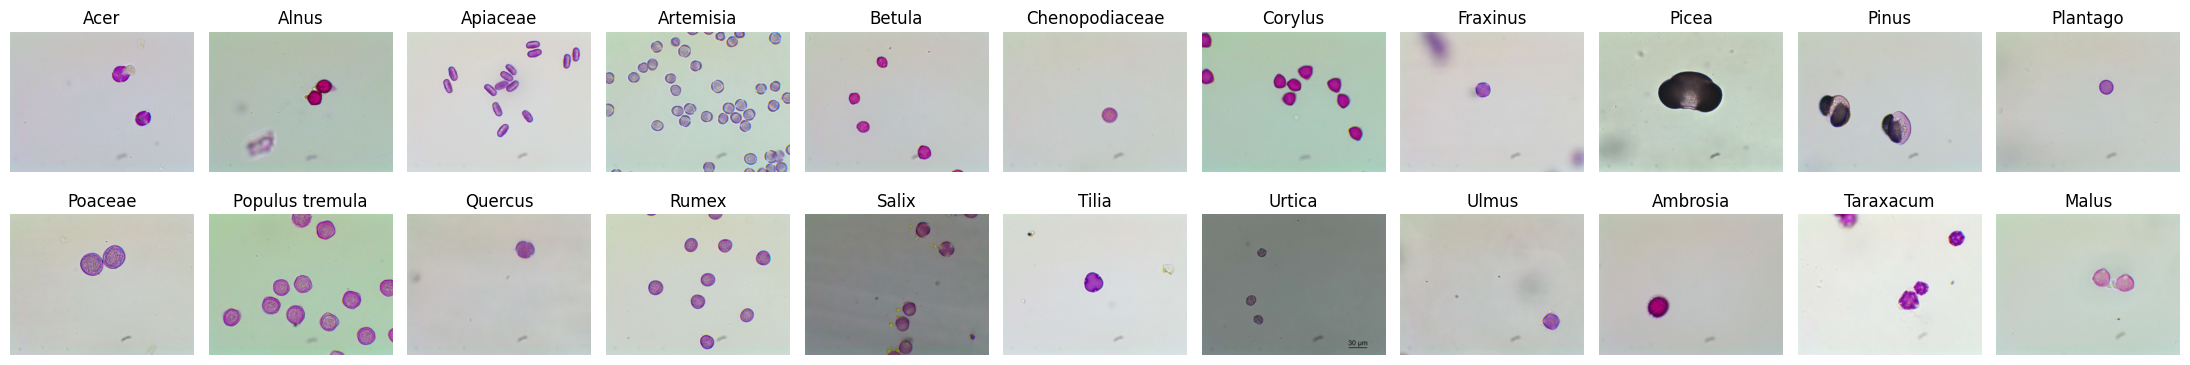

In [10]:
fig, axs = plt.subplots(nrows=2, ncols=11, figsize=(22, 4))
for ax, img_dir in zip(axs.flatten(), species_native+species_invasive):
    all_images = glob(os.path.join(DatasetPath.raw_images,img_dir, "*.jpg"))
    image_rgb = io.imread(all_images[0])
    ax.set_title(img_dir)
    ax.imshow(image_rgb)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

### Reference pollen dataset

The dataset with reference objects is in subfolder `objects_clean`

This dataset contains semi-manually extracted instances from raw images.

To repeat the automatic part of the algorithm of dividing samples into separate objects, you can use notebook ```Utils/Prepare Single Object Dataset.ipynb``` (Note the need to tune parameters for certain plant species).

In [11]:
print(f"Path of the reference pollen dataset: {DatasetPath.reference_images}")

Path of the reference pollen dataset: Dataset/pollen_dataset_2025_02_05\objects_clean


In [12]:
from common.img_utils import clean_background

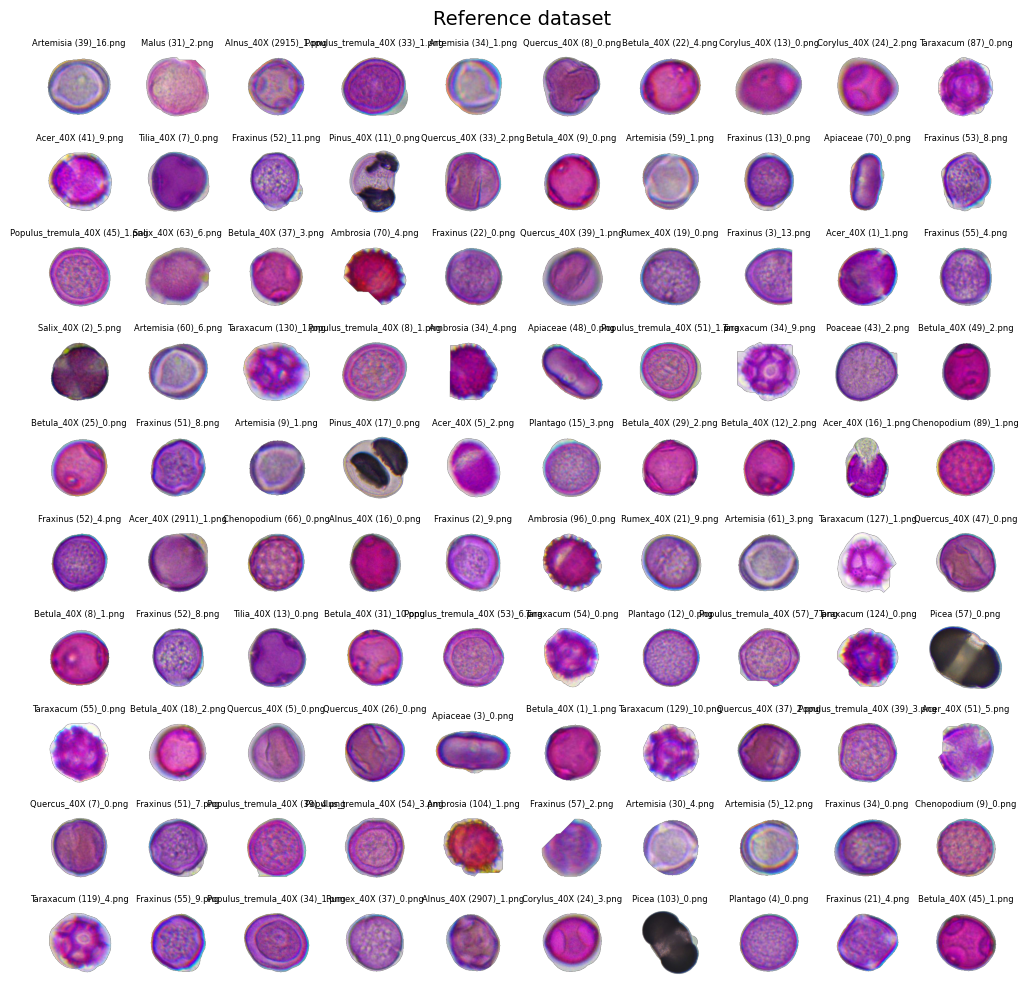

In [13]:
# Plot some objs
all_obj_images = glob(os.path.join(DatasetPath.reference_images,  "**", "*.png"), recursive=True)
random.shuffle(all_obj_images)
all_obj_images = all_obj_images[0:100]
n = math.ceil(len(all_obj_images) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n, n))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    image_rgb = clean_background(image_rgb)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path), fontsize=6)
for ax in axs.flatten()[len(all_obj_images):]:
    ax.set_visible(False)

fig.suptitle('Reference dataset', fontsize=14)
plt.tight_layout()
plt.show()

### Instance segmentation dataset (Test only)

To test instance segmentation model on real images we provide a labeled dataset in CVAT format.